# Google Drive and pip

In [ ]:
!pip install torch matplotlib "numpy<2"

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Configuration

In [ ]:
%%writefile configuration.py
# main.py
WIDTH = 1200
HEIGHT = 600
FPS = 30
NORMAL_SPEED = False
AIRPORT_ICAO = "EGBB"
RUNWAY_IN_USE = "RNWY33-RNWY15"
PLANES = []

# airport.py
MARK_FONT = None
DATA_FONT = None
NODE_LIST = []
EDGE_LIST = []
STAND_LIST = []
NODE_DICT = {}
EDGE_DICT = {}
STAND_DICT = {}
EXIT_DICT = {}

RENDER = False
RENDER_NODES = True
RENDER_EDGES = True
RENDER_STANDS = True
RENDER_DATA = True
RENDER_PREDICTION = False
PUSHBACK_PROBABILITY = 300
LANDING_PROBABILITY = 2000
MAX_FRAMES = 9_000

FRAME = 0
LAST_SPAWN = 0

COLLISION_THRESHOLD = 17 # Planes are 17x17 pixels
CONFLICT_THRESHOLD = 27

# plane.py
GROUND_IMG = "images/plane_ground.png"
AIRBORNE_IMG = "images/plane_airborne.png"

THRUST_CHANGE_RATE = 2      # Rate of thrust adjustment
MAX_SPEED = 150             # Maximum velocity in m/s
LANDING_DRAG = 0.04
TAKEOFF_DRAG = 0.05
GROUND_DRAG = 0.25
MAX_ACCELERATION = 5        # Maximum acceleration in m/s²
BRAKE_MULTIPLIER = 0.98     # Speed reduction factor when braking
FRICTION = 10               # Ground friction proportional to velocity
PIXEL_TO_METRE = 2.5        # 1 pixel = 2.5 meters
TIME_STEP = 1 / FPS         # Frame time (30 FPS)
MAX_TURN_ANGLE = 1          # Maximum turn angle in degrees
TURN_SPEED_SCALING = 0.05   # Scaling factor for speed-dependent turning
SLOW_DISTANCE = 10          # Distance at which to slow down to stop
SLOW_SPEED = 15             # knots
TAXI_SPEED = 25             # knots

# taxi_model.py
TAXI_MODEL_PATH = "/content/drive/MyDrive/data/taxi_model.pth"
TAXI_MODEL = None
MAX_DEVIATION = 5

# lstm_model.py
LSTM_MODEL_PATH = "/content/drive/MyDrive/data/lstm_model.pth"
LSTM_MODEL = None

Overwriting configuration.py


# Utils

In [ ]:
%%writefile utils.py
import math
import heapq
import configuration as config
import numpy as np
import random


class Node:
    def __init__(self, node_id, x, y):
        self.id = node_id
        self.x = x
        self.y = y

    def __repr__(self):
        return f"Node({self.id}, x={self.x}, y={self.y})"


class Edge:
    def __init__(self, start_node, end_node, distance, heading):
        self.id = f"{start_node.id}-{end_node.id}"
        self.start = start_node  # Node object
        self.end = end_node  # Node object
        self.distance = distance
        self.heading = heading

    def __repr__(self):
        return f"Edge({self.start.id} -> {self.end.id}, distance={self.distance:.2f}, heading={self.heading:.2f})"


class Stand:
    def __init__(self, stand_id, x, y, heading, parent):
        self.id = stand_id
        self.x = x
        self.y = y
        self.heading = heading
        self.parent = parent  # Edge object with order to follow to leave the stand
        self.available = True

    def __repr__(self):
        return f"Stand({self.id})"


def to_knots(mps):
    return mps * 1.94384


def to_mps(knots):
    return knots / 1.94384


def distance_between(point1, point2):
    return math.sqrt((point1.x - point2.x) ** 2 + (point1.y - point2.y) ** 2)


def distance_between_points(point1_x, point1_y, point2_x, point2_y):
    return math.sqrt((point1_x - point2_x) ** 2 + (point1_y - point2_y) ** 2)


def get_node_object(node_id):
    if isinstance(node_id, Node) or isinstance(node_id, Stand):
        return node_id
    return config.NODE_DICT[node_id]


def get_edge_object(edge_id):
    return config.EDGE_DICT[edge_id]


# def get_edge_object(node1, node2):
#     return config.EDGE_DICT[f"{node1}-{node2}"]


def dijkstra(start_node_id, end_node_id):
    """
    Dijkstra's algorithm for finding the shortest path in a graph.
    :param start_node_id: The ID of the starting Node.
    :param end_node_id: The ID of the target Node.
    :return: A tuple (path, distance) where path is a list of node IDs in the shortest path,
             and distance is the total distance of the path.
    """

    nodes = config.NODE_LIST
    edges = config.EDGE_LIST

    # Map nodes by their IDs for quick lookup
    node_map = {node.id: node for node in nodes}
    adjacency_list = {node.id: [] for node in nodes}

    # Build the adjacency list
    for edge in edges:
        adjacency_list[edge.start.id].append((edge.end.id, edge.distance))

    # Priority queue to store (distance, node_id)
    priority_queue = []
    heapq.heappush(priority_queue, (0, start_node_id))

    # Dictionary to store the shortest distance to each node
    distances = {node.id: float("inf") for node in nodes}
    distances[start_node_id] = 0

    # Dictionary to store the path
    previous_nodes = {node.id: None for node in nodes}

    while priority_queue:
        current_distance, current_node_id = heapq.heappop(priority_queue)

        # If we reach the end_node, stop early
        if current_node_id == end_node_id:
            break

        # Process each neighbour
        for neighbour_id, edge_distance in adjacency_list[current_node_id]:
            new_distance = current_distance + edge_distance
            if new_distance < distances[neighbour_id]:
                distances[neighbour_id] = new_distance
                previous_nodes[neighbour_id] = current_node_id
                heapq.heappush(priority_queue, (new_distance, neighbour_id))

    # Reconstruct the shortest path
    path = []
    current = end_node_id
    while current:
        path.append(current)
        current = previous_nodes[current]

    path.reverse()  # Reverse to get the path from start to end
    return path, distances[end_node_id]


def closest_point_on_line(x, y, a1, a2, b1, b2):
    # Vector AB
    ABx, ABy = b1 - a1, b2 - a2
    # Vector AP
    APx, APy = x - a1, y - a2
    # Length squared of AB
    AB_len_sq = ABx**2 + ABy**2

    if AB_len_sq == 0:  # A and B are the same point
        return (a1, a2, math.sqrt((x - a1) ** 2 + (y - a2) ** 2))

    # Projection factor t
    t = (APx * ABx + APy * ABy) / AB_len_sq
    # Clamp t to the range [0, 1]
    t = max(0, min(1, t))

    # Closest point on AB
    closest_x = a1 + t * ABx
    closest_y = a2 + t * ABy

    # Distance to closest point
    distance = math.sqrt((x - closest_x) ** 2 + (y - closest_y) ** 2)

    return (closest_x, closest_y, distance)


def get_taxi_state(plane):
    plane_x, plane_y = plane.x, plane.y
    next_node = get_node_object(plane.path[0])
    prev_node = get_node_object(plane.visited[-1])

    angles = [-90, 0, 90]
    distances = []

    for angle in angles:
        absolute_angle = (plane.heading + angle - 90) % 360
        radian_angle = math.radians(absolute_angle)

        dx, dy = math.cos(radian_angle), math.sin(radian_angle)

        current_x, current_y = plane_x, plane_y
        step_size = 1

        while True:
            current_x += dx * step_size
            current_y += dy * step_size

            _, _, distance_to_path = closest_point_on_line(
                current_x,
                current_y,
                prev_node.x,
                prev_node.y,
                next_node.x,
                next_node.y,
            )

            if distance_to_path >= config.MAX_DEVIATION:
                break

        distance_to_boundary = distance_between_points(
            plane_x, plane_y, current_x, current_y
        )
        distances.append(distance_to_boundary)

    distances = np.array(distances) / 150.0

    delta_x = next_node.x - plane_x
    delta_y = next_node.y - plane_y
    angle_to_target = (math.degrees(math.atan2(delta_y, delta_x)) + 360) % 360
    angle_diff = (angle_to_target - plane.heading + 90) % 360

    if angle_diff > 180:
        angle_diff -= 360
    turn_angle = angle_diff / 180

    speed = plane.speed / 100.0

    distance_to_target = (
        distance_between_points(plane_x, plane_y, next_node.x, next_node.y) / 150.0
    )

    thrust = plane.thrust / 100

    state = np.append(
        distances,
        [turn_angle, speed, distance_to_target, thrust],
    )

    return state.astype(np.float32)


def find_available_stand():
    available_stands = [stand for stand in config.STAND_LIST if stand.available]
    if available_stands:
        return random.choice(available_stands)
    return False


def is_exit_ahead(plane, exit):
    exit_node = get_node_object(exit)
    radian_heading = math.radians(plane.heading)
    plane_to_exit_x = exit_node.x - plane.x
    plane_to_exit_y = exit_node.y - plane.y
    dot_product = plane_to_exit_x * math.sin(
        radian_heading
    ) + plane_to_exit_y * -math.cos(radian_heading)
    return dot_product > 0


def get_stand_entrance(stand):
    if stand is None:
        return None

    x, y, _ = closest_point_on_line(
        stand.x,
        stand.y,
        stand.parent.start.x,
        stand.parent.start.y,
        stand.parent.end.x,
        stand.parent.end.y,
    )

    return Node(f"{stand.id}-entrance", x, y)


def angle_between(point1, point2):
    return math.degrees(math.atan2(point2.y - point1.y, point2.x - point1.x))


def check_collision(plane_x, plane_y, other_x, other_y):
    distance = distance_between_points(plane_x, plane_y, other_x, other_y)
    return distance < config.COLLISION_THRESHOLD

def check_conflict(plane_x, plane_y, other_x, other_y):
    distance = distance_between_points(plane_x, plane_y, other_x, other_y)
    return distance < config.CONFLICT_THRESHOLD

def check_close(plane_x, plane_y, other_x, other_y):
    distance = distance_between_points(plane_x, plane_y, other_x, other_y)
    return distance < config.TOO_CLOSE_THRESHOLD

def get_distance_to_end(path):
    distance = 0
    for i in range(len(path) - 1):
        start_node = get_node_object(path[i])
        end_node = get_node_object(path[i + 1])
        distance += distance_between(start_node, end_node)
    return distance


def snap_to_path(path, x, y):
    closest_distance = float("inf")
    closest_x, closest_y = None, None

    for i in range(len(path) - 1):
        start_node = get_node_object(path[i])
        end_node = get_node_object(path[i + 1])

        x_snap, y_snap, distance = closest_point_on_line(
            x, y, start_node.x, start_node.y, end_node.x, end_node.y
        )

        if distance < closest_distance:
            closest_distance = distance
            closest_x, closest_y = x_snap, y_snap

    return closest_x, closest_y

import matplotlib.pyplot as plt
from IPython.display import clear_output

plt.ion()


def plot(scores, mean_scores):
    clear_output(wait=True)  # Clears the previous output
    plt.figure(figsize=(8, 5))  # Set figure size
    plt.clf()
    plt.title("Training Progress")
    plt.xlabel("Number of Games")
    plt.ylabel("Score")
    plt.axhline(0, color="gray", linewidth=0.5)
    plt.plot(scores, label="Score", color="blue")
    plt.plot(mean_scores, label="Mean Score", color="red")
    plt.legend()

    if scores:
        plt.text(len(scores) - 1, scores[-1], f"{scores[-1]:.3f}", color="blue")
    if mean_scores:
        plt.text(
            len(mean_scores) - 1, mean_scores[-1], f"{mean_scores[-1]:.3f}", color="red"
        )

    plt.show()

Overwriting utils.py


# Future Prediction and Driving Models

In [ ]:
%%writefile model_future_LSTM.py
import torch
import torch.nn as nn
import configuration as config
import math
from utils import get_node_object, distance_between, angle_between


class PlaneTrajectoryLSTM(nn.Module):
    def __init__(self, input_size=11, hidden_size=128, num_layers=2, output_size=3, dropout=0.2):
        super(PlaneTrajectoryLSTM, self).__init__()

        # LSTM Layer
        self.lstm = nn.LSTM(
            input_size=input_size,  # Number of input features per timestep
            hidden_size=hidden_size,  # Number of hidden units
            num_layers=num_layers,  # Number of stacked LSTM layers
            batch_first=True,  # Input/output tensors will have shape (batch, seq, feature)
            dropout=(
                dropout if num_layers > 1 else 0
            ),  # Apply dropout only if more than 1 layer
        )

        # Fully Connected Layer (Output Layer)
        self.fc = nn.Linear(
            hidden_size, output_size * 3
        )  # 3 time horizons - Maps LSTM output to (x, y, heading)

    def forward(self, x):
        # LSTM Forward Pass
        lstm_out, _ = self.lstm(x)  # lstm_out: (batch, seq_len, hidden_size)

        # Predict multiple future points using the last timestep
        out = self.fc(lstm_out[:, -1, :])  # (batch, 9)

        # Reshape to (batch_size, 3 future steps, 3 outputs each)
        out = out.view(-1, 3, 3)

        return out

    def load(self):
        self.load_state_dict(torch.load(config.LSTM_MODEL_PATH))
        self.eval()


def save_states_to_memory():
    for plane in config.PLANES:
        normalised_x = plane.x / config.WIDTH
        normalised_y = plane.y / config.HEIGHT
        normalised_heading = plane.heading / 360
        normalised_speed = plane.speed / config.MAX_SPEED

        # One-hot encoding
        state_encoding = {
            "preparing": [1, 0, 0, 0],  # Stationary
            "parked": [1, 0, 0, 0],  # Stationary
            "taxiing": [0, 1, 0, 0],  # Taxiing
            "parking": [0, 1, 0, 0],  # Taxiing
            "landing": [0, 0, 1, 0],  # Landing Phase
            "rollout": [0, 0, 1, 0],  # Landing Phase
            "pushback": [0, 0, 0, 1],  # Active Movement
            "takeoff": [0, 0, 0, 1],  # Active Movement
        }
        encoded_state = state_encoding.get(plane.state, [0, 0, 0, 0])

        # Distance and direction
        if not plane.path:
            distance = 0
            direction = plane.heading
        else:
            node = get_node_object(plane.path[0])
            distance = distance_between(plane, node)
            direction = angle_between(plane, node)

        # Clipping distance for normalisation
        clipped_distance = min(distance, 200)
        normalised_distance = clipped_distance / 200

        # Sin/Cos for smooth directional encoding
        direction_rad = math.radians(direction)
        direction_sin = math.sin(direction_rad)
        direction_cos = math.cos(direction_rad)

        # Final state vector
        state = [
            normalised_x,
            normalised_y,
            normalised_heading,
            normalised_speed,
            *encoded_state,  # One-hot encoded state
            normalised_distance,
            direction_sin,  # Replaces normalised_direction
            direction_cos,  # Replaces normalised_direction
        ]

        # Memory management
        plane.memory.append(state)
        if len(plane.memory) > 30:
            plane.memory.popleft()

Overwriting model_future_LSTM.py


In [ ]:
%%writefile model_taxi_DQN.py
import torch
import torch.nn as nn
from configuration import TAXI_MODEL_PATH


class TaxiNet(nn.Module):
    def __init__(
        self,
        input_size=7,
        hidden_size=16,
        output_size_steering=3,
        output_size_throttle=3,
    ):
        super(TaxiNet, self).__init__()
        self.linear1 = nn.Linear(input_size, hidden_size)
        self.linear2 = nn.Linear(hidden_size, hidden_size)
        self.steering_head = nn.Linear(hidden_size, output_size_steering)
        self.throttle_head = nn.Linear(hidden_size, output_size_throttle)

    def forward(self, x):
        x = torch.relu(self.linear1(x))
        x = torch.relu(self.linear2(x))
        steering_output = self.steering_head(x)
        throttle_output = self.throttle_head(x)
        return steering_output, throttle_output

    def load(self, file_path=TAXI_MODEL_PATH):
        self.load_state_dict(torch.load(file_path))
        self.eval()

Overwriting model_taxi_DQN.py


# Airport

In [ ]:
%%writefile airport.py
import json
import math
import pygame
import configuration as config
from utils import *


def initialise_graph(json_file):
    nodes = {}
    edges = []
    stands = {}

    def load_nodes(data):
        for node in data["nodes"]:
            new_node = Node(node["id"], node["x"], node["y"])
            nodes[new_node.id] = new_node

        config.NODE_LIST = list(nodes.values())
        config.NODE_DICT = nodes

    def load_edges(data):
        for edge in data["edges"]:
            start_node = nodes[edge["from"]]
            end_node = nodes[edge["to"]]
            distance = calculate_distance(start_node, end_node)
            heading = calculate_heading(start_node, end_node)
            edges.append(Edge(start_node, end_node, distance, heading))
            edges.append(Edge(end_node, start_node, distance, (heading + 180) % 360))

        config.EDGE_LIST = edges
        config.EDGE_DICT = {edge.id: edge for edge in edges}

    def load_stands(data):
        for stand in data["stands"]:
            new_stand = Stand(
                stand["id"],
                stand["x"],
                stand["y"],
                stand["heading"],
                get_edge_object(stand["parent"]),
            )
            stands[new_stand.id] = new_stand

        config.STAND_LIST = list(stands.values())
        config.STAND_DICT = stands

    def load_runway_exits(data):
        for runway in data["runway_exits"]:
            config.EXIT_DICT[runway["id"]] = runway["exits"]

    def calculate_distance(node1, node2):
        return math.sqrt((node2.x - node1.x) ** 2 + (node2.y - node1.y) ** 2)

    def calculate_heading(node1, node2):
        angle = math.degrees(math.atan2(node2.y - node1.y, node2.x - node1.x))
        return (angle + 90) % 360

    with open(json_file, "r") as file:
        data = json.load(file)
        load_nodes(data)
        load_edges(data)
        load_stands(data)
        load_runway_exits(data)


def render_airport(screen: pygame.Surface):
    screen.blit(pygame.image.load(f"images/airport_{config.AIRPORT_ICAO}.jpg"), (0, 0))

    if config.RENDER_EDGES:
        draw_edges(screen)
    if config.RENDER_NODES:
        draw_nodes(screen)
    if config.RENDER_STANDS:
        draw_stands(screen)

    show_next_landing_aircraft(screen)


def show_next_landing_aircraft(screen):
    planes = [plane for plane in config.PLANES if plane.state == "landing"]

    touchdown = get_edge_object(config.RUNWAY_IN_USE).start
    distance = float("inf")

    if not planes:
        text = f"Next: N/A"
    else:
        for plane in planes:
            if distance_between(plane, touchdown) < distance:
                distance = distance_between(plane, touchdown)

        text = f"Next: {distance/config.PIXEL_TO_METRE:.0f}m"

    label = config.MARK_FONT.render(text, True, (255, 255, 255))
    screen.blit(label, (touchdown.x - 10, touchdown.y - 30))


def draw_nodes(screen):
    """
    Draw nodes as circles with their IDs labeled.
    :param screen: The pygame screen object.
    :param nodes: List of Node objects.
    :param font: A pygame font object for rendering text.
    """
    for node in config.NODE_LIST:
        # Draw a small circle at the node's location
        pygame.draw.circle(screen, (255, 0, 0), (node.x, node.y), 3)

        # Render the node ID as text to the right of the circle
        label = config.MARK_FONT.render(str(node.id), True, (255, 255, 255))
        screen.blit(
            label, (node.x + 5, node.y - 5)
        )  # Offset slightly to the right and up


def draw_edges(screen):
    """
    Draw edges as lines connecting the nodes.
    :param screen: The pygame screen object.
    :param edges: List of Edge objects.
    """
    for edge in config.EDGE_LIST:
        # Draw a line between the two nodes
        pygame.draw.line(
            screen,
            (0, 255, 0),
            (edge.start.x, edge.start.y),
            (edge.end.x, edge.end.y),
            1,
        )


def draw_stands(screen):
    """
    Draw stands as rectangles with their IDs labeled.
    :param screen: The pygame screen object.
    :param stands: List of Stand objects.
    :param font: A pygame font object for rendering text.
    """
    for stand in config.STAND_LIST:
        # Draw a rectangle at the stand's location
        pygame.draw.rect(screen, (0, 0, 255), (stand.x - 1, stand.y - 1, 2, 2))

        # Render the stand ID as text above the rectangle
        label = config.MARK_FONT.render(str(stand.id), True, (255, 255, 255))
        screen.blit(
            label, (stand.x - 5, stand.y - 15)
        )  # Offset slightly up from the rectangle


Overwriting airport.py


# Plane

In [ ]:
%%writefile plane.py
import math
import pygame
import numpy as np
import torch
from configuration import *
from utils import *
from collections import deque


class Plane:
    def __init__(self, x, y, heading, stand, state="preparing"):
        self.x = x
        self.y = y
        self.heading = heading
        self.thrust = 0
        self.speed = 0
        self.path = []
        self.visited = []
        self.state = state
        self.stand = stand
        self.drag = config.GROUND_DRAG
        if config.RENDER:
          if self.state == "preparing":
              self.image = pygame.image.load(config.GROUND_IMG)
              self.visited = [stand, get_stand_entrance(stand)]
          else:
              self.image = pygame.image.load(config.AIRBORNE_IMG)
        self.memory = deque(maxlen=30)
        self.future = None
        self.reward = 0
        self.prev_x = x
        self.prev_y = y
        self.ideal_action = 0
        self.crashed = False

    def __repr__(self):
        return (
            f"Plane(x={self.x}, y={self.y}, heading={self.heading}, state={self.state})"
        )

    def draw(self, window):
        if config.RENDER_PREDICTION:
            if self.future:
                opacities = [123, 82, 31]  # 60%, 40%, 20% of 255
                for i, pred in enumerate(self.future[:3]):
                    x, y, heading = pred
                    rotated_image = pygame.transform.rotate(self.image, -heading)
                    rotated_image.set_alpha(opacities[i])
                    rotated_rect = rotated_image.get_rect(center=(x, y))
                    window.blit(rotated_image, rotated_rect.topleft)

        rotated_image = pygame.transform.rotate(self.image, -self.heading)
        rotated_rect = rotated_image.get_rect(center=(self.x, self.y))
        window.blit(rotated_image, rotated_rect.topleft)

        if config.RENDER_DATA:
            data = config.DATA_FONT.render(
                f"{to_knots(self.speed):.0f} kts {self.thrust}%", True, (255, 255, 0)
            )
            window.blit(data, (self.x - 15, self.y - 20))

    def thrust_up(self):
        self.thrust += THRUST_CHANGE_RATE
        if self.thrust > 100:
            self.thrust = 100

    def thrust_down(self):
        self.thrust -= THRUST_CHANGE_RATE
        if self.thrust < 0:
            self.thrust = 0
            self.brake()

    def brake(self):
        self.speed *= BRAKE_MULTIPLIER
        if self.speed <= 0.1:
            self.speed = 0

    def update_speed(self):
        acceleration = (self.thrust / 100) * MAX_ACCELERATION

        self.speed += acceleration * TIME_STEP
        self.speed -= self.drag * self.speed * TIME_STEP

        if self.speed > MAX_SPEED:
            self.speed = MAX_SPEED
        elif self.speed < 0:
            self.speed = 0

    def move(self):
        self.update_speed()

        radian_heading = math.radians(self.heading)
        self.x += (self.speed / PIXEL_TO_METRE) * math.sin(radian_heading) * TIME_STEP
        self.y -= (self.speed / PIXEL_TO_METRE) * math.cos(radian_heading) * TIME_STEP

    def auto_move(self):
        if self.state == "takeoff":
            self.takeoff()
        if self.state == "pushback":
            self.pushback()
        if self.state == "taxiing" or self.state == "parking":
            self.taxi()
        if self.state == "landing":
            self.land()
        if self.state == "rollout":
            self.roll()
        if self.state == "parked":
            self.park()

    def get_turn_angle(self):
        if self.speed == 0:
            return 0
        return MAX_TURN_ANGLE / (1 + TURN_SPEED_SCALING * self.speed)

    def turn_left(self):
        turn_angle = self.get_turn_angle()
        self.heading = (self.heading - turn_angle) % 360

    def turn_right(self):
        turn_angle = self.get_turn_angle()
        self.heading = (self.heading + turn_angle) % 360

    # def taxi(self):
    #     if not self.path:
    #         return

    #     end_node = get_node_object(self.path[0])
    #     end_x, end_y = end_node.x, end_node.y

    #     distance_next = distance_between(self, end_node)
    #     distance_prev = (
    #         distance_between(self, end_node)
    #         if not self.visited
    #         else distance_between(self, get_node_object(self.visited[-1]))
    #     )

    #     if distance_next < SLOW_DISTANCE or distance_prev < SLOW_DISTANCE:
    #         self.speed = to_mps(SLOW_SPEED)
    #     else:
    #         self.speed = to_mps(TAXI_SPEED)

    #     radian_heading = math.atan2(end_y - self.y, end_x - self.x)
    #     self.heading = (math.degrees(radian_heading) + 90) % 360

    #     self.x += (self.speed / PIXEL_TO_METRE) * math.cos(radian_heading) * TIME_STEP
    #     self.y += (self.speed / PIXEL_TO_METRE) * math.sin(radian_heading) * TIME_STEP

    #     if distance_next < self.speed * TIME_STEP:
    #         self.x = end_x
    #         self.y = end_y
    #         self.speed = 0
    #         self.visited.append(self.path.pop(0))

    #         runway_path = get_edge_object(config.RUNWAY_IN_USE)

    #         if self.visited[-1] == runway_path.start.id:
    #             self.state = "takeoff"
    #             self.heading = runway_path.heading
    #             self.x = runway_path.start.x
    #             self.y = runway_path.start.y

    def taxi(self):
        if not self.path:
            return

        distance_next = distance_between(self, get_node_object(self.path[0]))

        if distance_next <= MAX_DEVIATION:
            self.visited.append(self.path.pop(0))

            if self.state == "taxiing":
                runway_path = get_edge_object(config.RUNWAY_IN_USE)

                if self.visited[-1] == runway_path.start.id:
                    self.state = "takeoff"
                    self.heading = runway_path.heading
                    return

            elif self.state == "parking":
                if self.visited[-1] == self.stand:
                    self.state = "parked"
                    return

        state = np.array(get_taxi_state(self)).astype(np.float32)
        state_tensor = torch.tensor(state, dtype=torch.float).unsqueeze(0)

        with torch.no_grad():
            steering_q_values, throttle_q_values = config.TAXI_MODEL(state_tensor)

        steering_action = torch.argmax(steering_q_values, dim=1).item()
        throttle_action = torch.argmax(throttle_q_values, dim=1).item()

        if steering_action == 1:
            self.turn_left()
        elif steering_action == 2:
            self.turn_right()

        if throttle_action == 1:
            self.thrust_up()
        elif throttle_action == 2:
            self.thrust_down()

        self.move()

    def pushback(self):
        pushback_line_start = self.stand.parent.start
        pushback_line_end = self.stand.parent.end
        point_x, point_y, distance = closest_point_on_line(
            self.x,
            self.y,
            pushback_line_start.x,
            pushback_line_start.y,
            pushback_line_end.x,
            pushback_line_end.y,
        )

        if distance <= 1:
            self.x = point_x
            self.y = point_y
            self.state = "taxiing"
            self.visited = [self.path.pop(0)]
            self.stand.available = True
            self.stand = None
            return

        radian_heading = math.radians(self.heading)
        self.x -= math.sin(radian_heading) / 10
        self.y += math.cos(radian_heading) / 10

    def takeoff(self):
        self.thrust = 100
        self.drag = config.TAKEOFF_DRAG
        if self.speed > to_mps(140):
            self.image = pygame.image.load(config.AIRBORNE_IMG)
        self.move()

        if (
            self.x < -1000
            or self.x > config.WIDTH + 1000
            or self.y < -1000
            or self.y > config.HEIGHT + 1000
        ):
            self.unload()

    def land(self, touch_down_deviation=110):
        self.move()

        runway_path = get_edge_object(config.RUNWAY_IN_USE)

        x_touchdown = runway_path.start.x + touch_down_deviation * math.sin(
            math.radians(runway_path.heading)
        )
        y_touchdown = runway_path.start.y - touch_down_deviation * math.cos(
            math.radians(runway_path.heading)
        )

        distance_to_touchdown = distance_between_points(
            self.x, self.y, x_touchdown, y_touchdown
        )

        if distance_to_touchdown < touch_down_deviation * 2:
            self.thrust = max(0, self.thrust - 1)

        if distance_to_touchdown < 1:
            self.state = "rollout"
            self.image = pygame.image.load(config.GROUND_IMG)
            self.thrust = 0

    def roll(self):
        self.move()
        exits = config.EXIT_DICT[config.RUNWAY_IN_USE]
        exits_ahead = [exit for exit in exits if is_exit_ahead(self, exit)]
        exits_passed = [exit for exit in exits if not is_exit_ahead(self, exit)]

        if self.speed < to_mps(30):
            dijkstra_path_start, path_distance_start = dijkstra(
                exits_ahead[0], self.stand.parent.start.id
            )
            dijkstra_path_end, path_distance_end = dijkstra(
                exits_ahead[0], self.stand.parent.end.id
            )

            self.visited = [exits_passed[-1]]

            if path_distance_start < path_distance_end:
                self.path = dijkstra_path_start
            else:
                self.path = dijkstra_path_end

            stand_entrance = get_stand_entrance(self.stand)
            self.path = self.path + [stand_entrance, self.stand]

            self.state = "parking"
            self.drag = config.GROUND_DRAG

    def park(self):
        if self.speed == 0:
            return

        self.heading = self.stand.heading
        self.thrust = 0
        self.visited = []
        self.path = []

        self.brake()
        self.move()

    def hold(self):
        self.thrust = 0
        self.brake()

    def unload(self):
        if self in config.PLANES:
            config.PLANES.remove(self)
        del self

    def predict_future_positions(self):
        if len(self.memory) < 10:
            return
        elif self.state == "parked":
            self.future = None
            return

        input_sequence = torch.tensor(
            list(self.memory)[-10:], dtype=torch.float32
        ).unsqueeze(
            0
        )  # Shape: (1, 10, 11)

        with torch.no_grad():
            predictions = config.LSTM_MODEL(input_sequence)

        predictions = predictions.squeeze(0).tolist()

        real_predictions = [
            [
                pred[0] * config.WIDTH,
                pred[1] * config.HEIGHT,
                pred[2] * 360,
            ]
            for pred in predictions
        ]

        if self.state in ["taxiing", "parking", "pushback", "preparing"]:
            for i in range(len(real_predictions)):
                x, y = snap_to_path(
                    self.visited + self.path,
                    real_predictions[i][0],
                    real_predictions[i][1],
                )
                real_predictions[i] = [x, y, real_predictions[i][2]]

        self.future = real_predictions

    def get_state(self):

        def get_self_state():
            speed = self.speed
            if self.path:
                distance_to_next = distance_between(self, get_node_object(self.path[0]))
                distance_to_end = get_distance_to_end(
                        [Node("", self.x, self.y)] + self.path
                    )
            else:
                distance_to_next = 0
                distance_to_end = 0

            return np.array(
                [
                    speed,
                    distance_to_next,
                    distance_to_end,
                ]
            ).astype(np.float32)

        def get_nearest_planes(num_planes, distance = 150):
            planes = config.PLANES.copy()
            planes.remove(self)

            distances = [(plane, distance_between(self, plane)) for plane in planes]
            distances = [item for item in distances if item[1] <= distance]
            distances.sort(key=lambda x: x[1])

            return distances[:num_planes]

        def heading_difference(h1, h2):
            diff = (h1 - h2 + 180) % 360 - 180
            return diff

        def absolute_angle_to(self, plane):
            delta_x = plane.x - self.x
            delta_y = plane.y - self.y
            angle_to_plane = (math.degrees(math.atan2(delta_y, delta_x)) + 360) % 360

            angle_diff = (angle_to_plane - self.heading - 270) % 360

            angle_diff -= 360 if angle_diff > 180 else 0

            return angle_diff

        def is_same_goal(plane):
            if not self.path or not plane.path:
                return 0

            own_goal = get_node_object(self.path[0])
            other_goal = get_node_object(plane.path[0])

            if own_goal == other_goal:
                return 1
            else:
                return 0

        def is_same_path(plane):
            own_path = [self.visited[-1:]] + self.path
            other_path = [plane.visited[-1:]] + plane.path

            for i in range(len(own_path) - 1):
                own_edge = (own_path[i], own_path[i + 1])
                for j in range(len(other_path) - 1):
                    other_edge = (other_path[j], other_path[j + 1])
                    if own_edge == other_edge:
                        return 1
            return 0

        def get_nearby_states(self_end_dist, num_features=5, num_planes=2):
            nearest_planes = get_nearest_planes(num_planes)
            nearby_plane_states = []

            for plane, distance in nearest_planes:
                speed = plane.speed
                angle = absolute_angle_to(self, plane)
                distance_end = get_distance_to_end(
                        [Node("", plane.x, plane.y)] + plane.path
                    )
                priority = 1 if distance_end < self_end_dist else 0

                radian_angle = np.radians(angle)
                angle = np.cos(radian_angle)
                invert_distance = 150 - distance
                relative_distance = max(0, invert_distance * angle)

                nearby_plane_states.append(
                        [
                            speed,
                            distance,
                            angle,
                            priority,
                            relative_distance,
                        ]
                    )

            while len(nearby_plane_states) < num_planes:
                nearby_plane_states.append(np.zeros(num_features).tolist())

            return np.array(nearby_plane_states).flatten().astype(np.float32).tolist()

        self_distance_to_end = get_self_state()[-1]

        return get_nearby_states(self_distance_to_end)


Overwriting plane.py


# Model

In [ ]:
%%writefile model.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import os


class MARLDQNModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=2):
        super(MARLDQNModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

    def save(self, file_name="model.pth"):
        model_folder_path = "./model"
        if not os.path.exists(model_folder_path):
            os.makedirs(model_folder_path)
        file_path = os.path.join(model_folder_path, file_name)
        torch.save(self.state_dict(), file_path)

    def load(self, file_name="model.pth"):
        model_folder_path = "./model"
        file_path = os.path.join(model_folder_path, file_name)
        if os.path.exists(file_path):
            self.load_state_dict(torch.load(file_path))
        else:
            print(
                f"Model file '{file_path}' does not exist. Starting with a new model."
            )


Overwriting model.py


# Simulation

In [ ]:
%%writefile simulation.py
import random
from plane import Plane
from airport import initialise_graph, render_airport
from utils import *
import configuration as config
from model_taxi_DQN import TaxiNet
from model_future_LSTM import PlaneTrajectoryLSTM, save_states_to_memory

if config.RENDER:
    import pygame

    pygame.init()
    config.MARK_FONT = pygame.font.Font(None, 12)
    config.DATA_FONT = pygame.font.Font(None, 14)


class Simulation:

    def __init__(self):
        if config.RENDER:
            self.screen = pygame.display.set_mode((config.WIDTH, config.HEIGHT))
            pygame.display.set_caption(f"Airport Simulation - {config.AIRPORT_ICAO}")

        initialise_graph(f"/content/drive/MyDrive/data/airport_{config.AIRPORT_ICAO}.json")

        taxi = TaxiNet()
        taxi.load()
        config.TAXI_MODEL = taxi

        lstm = PlaneTrajectoryLSTM()
        lstm.load()
        config.LSTM_MODEL = lstm

    def reset(self, episode):
        config.PLANES = []
        config.FRAME = 0
        config.LAST_SPAWN = 0

        for stand in config.STAND_LIST:
            stand.available = True

        if episode % 2 == 0:
            config.RUNWAY_IN_USE = "RNWY33-RNWY15"
        else:
            config.RUNWAY_IN_USE = "RNWY15-RNWY33"

        self.spawn_planes_at_stands()

    def spawn_planes_at_stands(self):
        available_stands = [stand for stand in config.STAND_LIST if stand.available]
        selected_stands = random.sample(
            available_stands, min(10, len(available_stands))
        )

        for stand in selected_stands:
            new_plane = Plane(stand.x, stand.y, stand.heading, stand)
            dijkstra_path_start, path_distance_start = dijkstra(
                stand.parent.start.id, get_edge_object(config.RUNWAY_IN_USE).start.id
            )
            dijkstra_path_end, path_distance_end = dijkstra(
                stand.parent.end.id, get_edge_object(config.RUNWAY_IN_USE).start.id
            )
            if path_distance_start < path_distance_end:
                dijkstra_path = [stand.parent.end.id] + dijkstra_path_start
            else:
                dijkstra_path = [stand.parent.start.id] + dijkstra_path_end
            new_plane.path = dijkstra_path
            config.PLANES.append(new_plane)
            stand.available = False

    def simulate_frame(self):
        for plane in config.PLANES:
            if plane.state == "preparing":
                if (
                    self.safe_to_pushback(plane)
                    and random.randint(1, config.PUSHBACK_PROBABILITY) == 1
                ):
                    plane.state = "pushback"

            plane.auto_move()
            if config.RENDER:
                plane.draw(self.screen)

    def is_future_conflict(self, plane):
        for other_plane in config.PLANES:
            if plane != other_plane and other_plane.future:
                if any(
                    check_conflict(
                        plane.future[i][0],
                        plane.future[i][1],
                        other_plane.future[i][0],
                        other_plane.future[i][1],
                    )
                    for i in range(3)
                ):
                    plane_path_distance = get_distance_to_end(
                        [Node("", plane.x, plane.y)] + plane.path
                    )
                    other_plane_path = get_distance_to_end(
                        [Node("", other_plane.x, other_plane.y)] + other_plane.path
                    )
                    if plane_path_distance < other_plane_path:
                        return False
                    else:
                        return True
        return False

    def safe_to_pushback(self, plane):
        position = get_stand_entrance(plane.stand)
        other_planes = [
            p
            for p in config.PLANES
            if p != plane
            and p.future
            and p.state not in ["landing", "takeoff", "rollout", "preparing"]
        ]
        for other_plane in other_planes:
            if any(
                check_conflict(
                    position.x,
                    position.y,
                    other_plane.future[i][0],
                    other_plane.future[i][1],
                )
                for i in range(3)
            ):
                return False
        return True

    def get_plane_states(self, planes):
        return [plane.get_state() for plane in planes]

    def get_taxiing_planes(self):
        return [plane for plane in config.PLANES if plane.state not in ["pushback", "preparing"]]

    def check_collisions(self):
        if len(config.PLANES) < 2:
            return False

        for plane in config.PLANES:
            for other_plane in config.PLANES:
                if plane != other_plane:
                    if check_collision(plane.x, plane.y, other_plane.x, other_plane.y):
                        plane.crashed = True
                        other_plane.crashed = True
                        return True
        return False

    def play_step(self, actions, planes):
        config.FRAME += 1

        if config.RENDER:
            for event in pygame.event.get():
                if event.type == pygame.QUIT:
                    pygame.quit()
                    quit()

        if config.FRAME % (config.FPS // 2) == 0:
            save_states_to_memory()
            for plane in config.PLANES:
                plane.predict_future_positions()

        if config.RENDER:
            render_airport(self.screen)

        for i, action in enumerate(actions):
            plane = planes[i]
            if action == 1: # Stop
                plane.hold()
                if self.is_future_conflict(plane):
                    plane.reward += 1.0
                else:
                    plane.reward += -1.0

            elif action == 0: # Go

                if self.is_future_conflict(plane):
                    plane.reward += -0.5
                else:
                    plane.reward += 0.5

        collision_occurred = self.check_collisions()

        self.simulate_frame()

        # Get next states BEFORE unloading finished planes.
        next_states = self.get_plane_states(planes)

        dones = []
        for plane in planes:
            if plane.state not in [
                "preparing",
                "pushback",
                "taxiing",
            ]:
                plane.reward += 50
                dones.append(True)
            elif plane.crashed:
                plane.reward += -100
                dones.append(True)
            else:
                dones.append(False)

        rewards = [plane.reward for plane in planes]

        # Unload finished planes AFTER recording their next state and terminal flag.
        plane_copy = config.PLANES.copy()
        for plane in plane_copy:
            plane.reward = 0
            if plane.state not in ["preparing", "pushback", "taxiing"] or plane.crashed:
                plane.unload()

        episode_done = (
            (config.FRAME >= config.MAX_FRAMES)
            or (len(config.PLANES) == 0)
            or collision_occurred
        )

        if config.RENDER:
            pygame.display.flip()

        return next_states, rewards, dones, episode_done


Overwriting simulation.py


# Agent (Prioritized Experience Replay)

In [ ]:
%%writefile per_agent.py
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from model import MARLDQNModel
import configuration as config
from utils import plot


class MARLDQNAgent:
    def __init__(
        self,
        input_dim,
        hidden_dim,
        lr,
        gamma,
        epsilon,
        epsilon_min,
        epsilon_decay,
        device,
        max_memory,
        batch_size,
        alpha = 0.8,
        beta = 0.4,
        epsilon_priority=1e-5,
    ):
        self.device = device
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.online_net = MARLDQNModel(input_dim, hidden_dim).to(device)
        self.target_net = MARLDQNModel(input_dim, hidden_dim).to(device)
        self.optimizer = optim.Adam(self.online_net.parameters(), lr=lr)
        self.update_target_network()
        self.memory = []
        self.priorities = []
        self.max_memory = max_memory
        self.batch_size = batch_size
        self.alpha = alpha
        self.beta = beta
        self.epsilon_priority = epsilon_priority

    def update_target_network(self):
        self.target_net.load_state_dict(self.online_net.state_dict())

    def store_transition(self, state, action, reward, next_state, done):
        if len(self.memory) >= self.max_memory:
            self.memory.pop(0)
            self.priorities.pop(0)

        self.memory.append((state, action, reward, next_state, done))

        if self.priorities:
            max_priority = max(self.priorities)
            if isinstance(max_priority, np.ndarray):
                max_priority = max_priority.item()
        else:
            max_priority = 1.0  # Default priority for the first transition

        self.priorities.append(max_priority)

    # Convert priorities to sampling probabilities.
    def _calculate_priorities(self):
        priorities = np.array(self.priorities) ** self.alpha
        probabilities = priorities / priorities.sum()
        return probabilities

    def select_action(self, state):
        if np.random.rand() < self.epsilon:
            return np.random.randint(0, 2)
        state_tensor = (
            torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(self.device)
        )
        with torch.no_grad():
            q_values = self.online_net(state_tensor)
        return int(torch.argmax(q_values, dim=1).item())

    # Sample a batch of transitions based on priorities.
    def sample_memory(self):
        if len(self.memory) < self.batch_size:
            return None

        probabilities = self._calculate_priorities()
        indices = np.random.choice(len(self.memory), self.batch_size, p=probabilities)
        samples = [self.memory[i] for i in indices]
        states, actions, rewards, next_states, dones = zip(*samples)
        return states, actions, rewards, next_states, dones, indices

    # Update priorities based on TD errors.
    def _update_priorities(self, indices, td_errors):
        for idx, error in zip(indices, td_errors):
            if isinstance(error, np.ndarray):
                error = error.item()

            self.priorities[idx] = abs(error) + self.epsilon_priority

    def train_step(self):
        sample = self.sample_memory()

        if sample is None:
            return 0

        states, actions, rewards, next_states, dones, indices = sample

        states = torch.tensor(states, dtype=torch.float32).to(self.device)
        actions = torch.tensor(actions, dtype=torch.int64).unsqueeze(1).to(self.device)
        rewards = (torch.tensor(rewards, dtype=torch.float32).unsqueeze(1).to(self.device))
        next_states = torch.tensor(next_states, dtype=torch.float32).to(self.device)
        dones = torch.tensor(dones, dtype=torch.float32).unsqueeze(1).to(self.device)

        q_values = self.online_net(states).gather(1, actions)
        with torch.no_grad():
            next_q_values = self.target_net(next_states).max(1)[0].unsqueeze(1)
            target_q_values = rewards + self.gamma * next_q_values * (1 - dones)

        # Compute temporal difference errors
        td_errors = (target_q_values - q_values).abs().detach().cpu().numpy()

        # Update priorities
        self._update_priorities(indices, td_errors)

        # Compute importance sampling weights
        priorities = np.array(self.priorities, dtype=np.float32)[indices]
        probabilities = (priorities ** self.alpha) / (np.array(self.priorities) ** self.alpha).sum()
        weights = (len(self.memory) * probabilities) ** (-self.beta)
        weights /= weights.max()

        # Compute loss with importance sampling weights
        weights = torch.tensor(weights, dtype=torch.float32).unsqueeze(1).to(self.device)
        loss = (weights * nn.MSELoss()(q_values, target_q_values)).mean()

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay

        return loss.item()

def report_reward_distribution(agent):
        # Initialize dictionaries to store positive and negative rewards for each action
        action_rewards = {
            0: {"positive": 0, "negative": 0},
            1: {"positive": 0, "negative": 0}
        }

        # Iterate through the agent's memory and categorize rewards by action
        for memory in agent.memory:
            _, action, reward, _, _ = memory
            if reward >= 0:
                action_rewards[action]["positive"] += 1
            else:
                action_rewards[action]["negative"] += 1

        # Print the reward distribution report
        print("Reward Distribution Report (Grouped by Actions):")
        for action in action_rewards:
            total_rewards = action_rewards[action]["positive"] + action_rewards[action]["negative"]
            if total_rewards > 0:
                positive_percent = (action_rewards[action]["positive"] / total_rewards) * 100
                negative_percent = (action_rewards[action]["negative"] / total_rewards) * 100
            else:
                positive_percent = 0
                negative_percent = 0

            print(f"Action {action}:")
            print(f"  Positive Rewards: {action_rewards[action]['positive']} ({positive_percent:.2f}%)")
            print(f"  Negative Rewards: {action_rewards[action]['negative']} ({negative_percent:.2f}%)")
        print(f"Total Memories: {len(agent.memory)}")
        print("-" * 30)

from simulation import Simulation
def train(num_episodes, env: Simulation, agent: MARLDQNAgent, batch_size, target_update_freq):
    """
    Assumptions:
        - env.reset() initialises the simulation.
        - env.get_taxiing_planes() returns a list of planes still taxiing.
        - Each plane has a get_state() method.
        - env.step(actions) applies actions to the environment and returns next_states, rewards, and a done flag.
    """
    record = float("-inf")
    scores = []
    mean_scores = []

    # max_frames = 15_000
    # current_frames = 1_000
    # config.MAX_FRAMES = current_frames

    for episode in range(1, num_episodes):
        score = 0
        env.reset(episode)
        game_over = False
        # Get only planes that are currently taxiing
        planes = env.get_taxiing_planes()

        while not game_over and len(config.PLANES) > 0:
            # STEP 1: COLLECT STATES FROM ALL TAXIING PLANES
            states = env.get_plane_states(planes)
            # states = [plane.get_state() for plane in planes]

            # STEP 2: INFER ACTIONS FROM THE SHARED MODEL
            actions = [agent.select_action(state) for state in states]

            # STEP 3: APPLY ACTIONS & GET NEXT STATE + REWARD
            next_states, rewards, dones, game_over = env.play_step(actions, planes)

            # STEP 4: STORE EXPERIENCES IN THE SHARED REPLAY BUFFER
            for state, action, reward, next_state, done in zip(
                states, actions, rewards, next_states, dones
            ):
                # Here, the same done flag is used for all transitions; if needed you can customise per plane.
                agent.store_transition(state, action, reward, next_state, done)

            # STEP 5: UPDATE STATES (ONLY FOR TAXIING PLANES)
            planes = env.get_taxiing_planes()

            score += sum(rewards)

        score /= config.FRAME
        scores.append(score)
        mean_scores.append(np.mean(scores[-50:]))

        # if current_frames < max_frames:
        #     current_frames += 50
        #     config.MAX_FRAMES = current_frames

        if score > record:
            record = score
            agent.online_net.save("best_model.pth")

        if episode % 100 == 0:
            agent.online_net.save(f"model_{episode}.pth")

        # STEP 6: TRAIN THE SHARED MODEL (Long-term Memory Training)
        if len(agent.memory) >= batch_size:
            loss = agent.train_step()
            plot(scores, mean_scores)
            print(f"Episode {episode} \t Loss: {loss:.0f} \t Score: {score:.0f}")
            report_reward_distribution(agent)

        # STEP 7: PERIODICALLY UPDATE THE TARGET NETWORK
        if episode % target_update_freq == 0:
            agent.update_target_network()

def test_model(env: Simulation, model_file, input_dim, hidden_dim, num_episodes = 1):

    model = MARLDQNModel(input_dim, hidden_dim)
    model.load(model_file)
    model.eval

    for episode in range(num_episodes):
        env.reset(episode)

        game_over = False
        planes = env.get_taxiing_planes()

        while not game_over and len(config.PLANES) > 0:
            states = env.get_plane_states(planes)

            actions = []
            for state in states:
                state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
                q_values = model(state_tensor)
                actions.append(int(torch.argmax(q_values, dim=1).item()))

            _, _, _, game_over = env.play_step(actions, planes)

            planes = env.get_taxiing_planes()

Overwriting per_agent.py


# Agent (Balanced Experience Replay)

In [ ]:
%%writefile agent.py
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from model import MARLDQNModel
import configuration as config
from utils import plot


class MARLDQNAgent:
    def __init__(
        self,
        input_dim,
        hidden_dim,
        lr,
        gamma,
        epsilon,
        epsilon_min,
        epsilon_decay,
        device,
        max_memory,
        batch_size
    ):
        self.device = device
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.online_net = MARLDQNModel(input_dim, hidden_dim).to(device)
        self.target_net = MARLDQNModel(input_dim, hidden_dim).to(device)
        self.optimizer = optim.Adam(self.online_net.parameters(), lr=lr)
        self.update_target_network()
        self.good_stop = []
        self.good_go = []
        self.bad_stop = []
        self.bad_go = []
        self.terminal = []
        self.max_memory = max_memory
        self.batch_size = batch_size

    def update_target_network(self, tau = 0.005):
        # self.target_net.load_state_dict(self.online_net.state_dict())

        # Use Soft Updates for the Target Network Instead of Hard Updates
        for target_param, online_param in zip(self.target_net.parameters(), self.online_net.parameters()):
            target_param.data.copy_(tau * online_param.data + (1 - tau) * target_param.data)


    def store_transition(self, state, action, reward, next_state, done):
        if done:
            self.terminal.append((state, action, reward, next_state, done))
        if action == 1 and reward >= 0:
            self.good_stop.append((state, action, reward, next_state, done))
        elif action == 1 and reward < 0:
            self.bad_stop.append((state, action, reward, next_state, done))
        elif action == 0 and reward >= 0:
            self.good_go.append((state, action, reward, next_state, done))
        elif action == 0 and reward < 0:
            self.bad_go.append((state, action, reward, next_state, done))
        else:
            self.terminal.append((state, action, reward, next_state, done))

        if len(self.good_stop) > self.max_memory:
            self.good_stop.pop(0)
        if len(self.good_go) > self.max_memory:
            self.good_go.pop(0)
        if len(self.bad_stop) > self.max_memory:
            self.bad_stop.pop(0)
        if len(self.bad_go) > self.max_memory:
            self.bad_go.pop(0)

    def select_action(self, state):
        if np.random.rand() < self.epsilon:
            return np.random.randint(0, 2)
        state_tensor = (
            torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(self.device)
        )
        with torch.no_grad():
            q_values = self.online_net(state_tensor)
        return int(torch.argmax(q_values, dim=1).item())

    def sample_memory(self):
      buffers = [self.good_stop, self.bad_stop, self.good_go, self.bad_go, self.terminal]
      num_buffers = len(buffers)

      # Number of samples per buffer
      per_buffer = self.batch_size // num_buffers

      sampled_batches = []

      for buffer in buffers:
          if len(buffer) >= per_buffer:
              # Enough samples, sample indices without replacement
              indices = np.random.choice(len(buffer), per_buffer, replace=False)
              sampled_batches.extend([buffer[i] for i in indices])
          else:
              if len(buffer) == 0:
                  continue
              # Not enough samples, take all and fill the rest
              sampled_batches.extend(buffer)
              missing = per_buffer - len(buffer)
              if missing > 0:
                  # Sample indices with replacement
                  indices = np.random.choice(len(buffer), missing, replace=True)
                  sampled_batches.extend([buffer[i] for i in indices])

      # Ensure we return exactly `batch_size` samples (in case of rounding issues)
      sampled_batches = sampled_batches[:self.batch_size]
      np.random.shuffle(sampled_batches)

      # Unzip sampled data
      states, actions, rewards, next_states, dones = zip(*sampled_batches)

      # Convert to NumPy arrays (if states and next_states are already arrays, this will work)
      states = np.array(states)
      actions = np.array(actions)
      rewards = np.array(rewards)
      next_states = np.array(next_states)
      dones = np.array(dones)

      return states, actions, rewards, next_states, dones

    def train_step(self):
        states, actions, rewards, next_states, dones = self.sample_memory()

        states = torch.tensor(states, dtype=torch.float32).to(self.device)
        actions = torch.tensor(actions, dtype=torch.int64).unsqueeze(1).to(self.device)
        rewards = (torch.tensor(rewards, dtype=torch.float32).unsqueeze(1).to(self.device))
        next_states = torch.tensor(next_states, dtype=torch.float32).to(self.device)
        dones = torch.tensor(dones, dtype=torch.float32).unsqueeze(1).to(self.device)

        q_values = self.online_net(states).gather(1, actions)
        # with torch.no_grad():
        #     next_q_values = self.target_net(next_states).max(1)[0].unsqueeze(1)
        #     target_q_values = rewards + self.gamma * next_q_values * (1 - dones)
        with torch.no_grad():
            # Step 1: Use the online network to select the best action
            best_actions = self.online_net(next_states).argmax(1, keepdim=True)

            # Step 2: Use the target network to evaluate the Q-value of that best action
            next_q_values = self.target_net(next_states).gather(1, best_actions)

            # Step 3: Compute target Q-values
            target_q_values = rewards + self.gamma * next_q_values * (1 - dones)

        loss = nn.MSELoss()(q_values, target_q_values)
        self.optimizer.zero_grad()
        torch.nn.utils.clip_grad_norm_(self.online_net.parameters(), max_norm=1.0)
        loss.backward()
        self.optimizer.step()

        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay

        return loss.item()

from simulation import Simulation
def train(num_episodes, env: Simulation, agent: MARLDQNAgent, batch_size, target_update_freq):
    """
    Assumptions:
        - env.reset() initialises the simulation.
        - env.get_taxiing_planes() returns a list of planes still taxiing.
        - Each plane has a get_state() method.
        - env.step(actions) applies actions to the environment and returns next_states, rewards, and a done flag.
    """
    record = float("-inf")
    scores = []
    mean_scores = []

    # max_frames = 15_000
    # current_frames = 1_000
    # config.MAX_FRAMES = current_frames

    for episode in range(1, num_episodes):
        score = 0
        env.reset(episode)
        game_over = False

        planes = env.get_taxiing_planes()

        while not game_over and len(config.PLANES) > 0:
            # STEP 1: COLLECT STATES FROM ALL TAXIING PLANES
            states = env.get_plane_states(planes)
            # states = [plane.get_state() for plane in planes]

            # STEP 2: INFER ACTIONS FROM THE SHARED MODEL
            actions = [agent.select_action(state) for state in states]

            # STEP 3: APPLY ACTIONS & GET NEXT STATE + REWARD
            next_states, rewards, dones, game_over = env.play_step(actions, planes)

            # STEP 4: STORE EXPERIENCES IN THE SHARED REPLAY BUFFER
            for state, action, reward, next_state, done in zip(
                states, actions, rewards, next_states, dones
            ):
                # Here, the same done flag is used for all transitions; if needed you can customise per plane.
                agent.store_transition(state, action, reward, next_state, done)

            # STEP 5: UPDATE STATES (ONLY FOR TAXIING PLANES)
            planes = env.get_taxiing_planes()

            score += sum(rewards)

        score /= config.FRAME
        scores.append(score)
        mean_scores.append(np.mean(scores[-25:]))

        # if current_frames < max_frames:
        #     current_frames += 50
        #     config.MAX_FRAMES = current_frames

        if score > record:
            record = score
            agent.online_net.save("best_model.pth")

        if episode % 100 == 0:
            agent.online_net.save(f"model_{episode}.pth")

        # STEP 6: TRAIN THE SHARED MODEL (Long-term Memory Training)
        loss = agent.train_step()
        plot(scores, mean_scores)
        print(f"Episode {episode} \t Loss: {loss:.3f} \t Score: {score:.3f}")
        print(f"Good Go:  \t{len(agent.good_go)}")
        print(f"Bad Go:   \t{len(agent.bad_go)}")
        print(f"Good Stop:\t{len(agent.good_stop)}")
        print(f"Bad Stop: \t{len(agent.bad_stop)}")

        # STEP 7: PERIODICALLY UPDATE THE TARGET NETWORK
        if episode % target_update_freq == 0:
            agent.update_target_network()

def test_model(env: Simulation, model_file, input_dim, hidden_dim, num_episodes = 1):

    model = MARLDQNModel(input_dim, hidden_dim)
    model.load(model_file)
    model.eval

    for episode in range(num_episodes):
        env.reset(episode)

        game_over = False
        planes = env.get_taxiing_planes()

        while not game_over and len(config.PLANES) > 0:
            states = env.get_plane_states(planes)

            actions = []
            for state in states:
                state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
                q_values = model(state_tensor)
                actions.append(int(torch.argmax(q_values, dim=1).item()))

            _, _, _, game_over = env.play_step(actions, planes)

            planes = env.get_taxiing_planes()

Overwriting agent.py


# Main

In [ ]:
import torch
from agent import MARLDQNAgent, train, test_model
from simulation import Simulation


def main():
    # # Hyperparameters
    # input_dim = 8
    # hidden_dim = 32
    # lr = 0.001
    # gamma = 0.99
    # epsilon = 1.0
    # epsilon_min = 0.05
    # epsilon_decay = 0.98
    # num_episodes = 1_000
    # batch_size = 1025
    # target_update_freq = 10
    # device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    # max_memory = 100_000

    # Farid's Hyperparameters
    input_dim = 10
    hidden_dim = 32
    lr = 0.001
    gamma = 0.99 # Research more
    epsilon = 1.0
    epsilon_min = 0.1
    epsilon_decay = 0.999
    num_episodes = 1_000_000
    batch_size = 60
    target_update_freq = 10
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    max_memory = 50_000

    # Instantiate environment and agent
    env = Simulation()
    agent = MARLDQNAgent(
        input_dim, hidden_dim, lr, gamma, epsilon, epsilon_min, epsilon_decay, device, max_memory, batch_size
    )

    train(num_episodes, env, agent, batch_size, target_update_freq)
    # test_model(env, "best_model.pth", input_dim, hidden_dim)


pygame 2.6.1 (SDL 2.28.4, Python 3.11.11)
Hello from the pygame community. https://www.pygame.org/contribute.html


# Training...

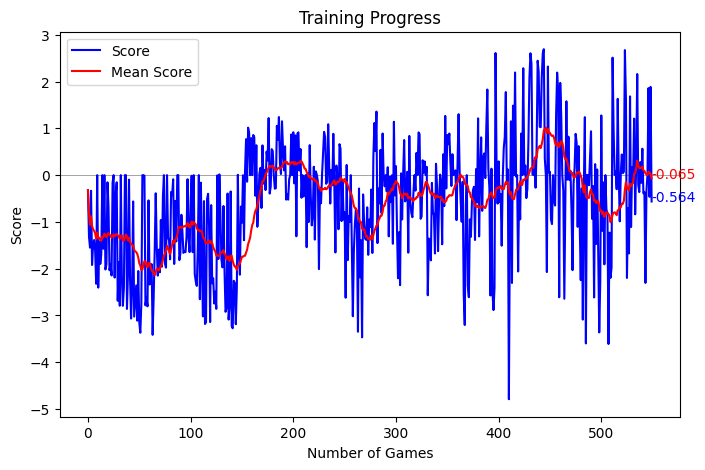

Episode 550 	 Loss: 430.283 	 Score: -0.564
Good Go:  	50000
Bad Go:   	50000
Good Stop:	50000
Bad Stop: 	50000


In [ ]:
if __name__ == "__main__":
    main()